In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
# Imports
from Experiment_1.TwoAFCTask import generate_trials
#from Experiment_5.SiegelMillerTask import generate_trials
import networkx as nx
import pandas as pd
import matplotlib
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import seaborn as sns
from Experiment_1.net import *
import os
import numpy as np
import statsmodels.api as sm
import scipy.optimize as opt
import math
#from psychometrics import *
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import networkx as nx
from sklearn.cluster import KMeans

plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE

matplotlib.rcParams['axes.linewidth'] = .75

2afc


In [3]:
def compute_var(variance, n):
    return np.sum(variance[n:])

def compute_p(k, null_k):
    return (np.sum(null_k < k) / len(null_k))

In [4]:
# Load data
df_list = []
for filename in os.listdir('Experiment_1/Results_1'):
    f = os.path.join('Experiment_1/Results_1', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list, ignore_index=True)
original_df = original_df[original_df.mse_z < .035]
original_df = original_df[original_df.n==100]

In [5]:
df = original_df.copy()

# Restrict to networks with dim and compute variance above dim
dim =2
df = df[df.dim == dim]
df = df[df.k >= dim]
df['var'] = df.variance.apply(lambda x: compute_var(x, dim))
df['k_inertia'] = df.inertia.apply(lambda x: x[dim - 1])
#df['var'] = np.log(df['var'])
df.sort_values('var', ascending=True)

,model_id,w_rec,w_in,w_out,bias,mse_z,weight_decay,threshold,sigma_rec,lambda_std,...,lvar,dim,k,p_value,inertia,activity_std,null_inertia,variance,var,k_inertia
4201,zZybp1dH,"[[0.00039699546, 0.0058500995, -0.027521536, 0...","[[0.05804312, -0.08831401], [0.056685843, -0.0...","[[0.25315684, 0.19702563, 0.03155379, 0.211325...","[0.09620439, 0.092840165, 0.102042116, 0.09329...",0.030264,0.002,0.025,0.0,1.0,...,2.154435,2,2,0.0,"[0.9191581597222223, 4.0524264176686605e-06, 2...",0.014410,"[[0.9746496826397203, 0.9689103881949498, 0.98...","[0.92076623, 0.07923076, 1.6201794e-06, 6.2786...",0.000003,0.000004
4500,AXTpYDvk,"[[0.0050830278, 0.0018884875, 0.0053543304, -0...","[[-0.044528265, 0.039660826], [-0.0444862, 0.0...","[[0.022030562, 0.031188445, 0.036533512, 0.168...","[0.09207177, 0.0914266, 0.09225431, 0.09851982...",0.028169,0.002,0.025,0.0,1.0,...,3.162278,2,2,0.0,"[0.8957154423364099, 6.242936066967988e-06, 3....",0.140556,"[[0.9868248197205965, 0.9971403969232333, 0.99...","[0.92150134, 0.07849373, 3.179441e-06, 1.21829...",0.000005,0.000006
4203,yMauKlsy,"[[0.0016033401, 0.0003251426, -0.018807208, 0....","[[-0.05237785, 0.040564265], [-0.052296273, 0....","[[0.027944116, 0.036914397, 0.19807988, 0.0334...","[0.095831014, 0.09515084, 0.09447777, 0.095677...",0.027178,0.002,0.025,0.0,1.0,...,2.154435,2,2,0.0,"[0.9075316840277777, 6.163681877983941e-06, 3....",0.056414,"[[0.9944313106690003, 0.9978564614571037, 0.99...","[0.92203057, 0.07796457, 3.1521963e-06, 9.9494...",0.000005,0.000006
4515,9PePRd9Y,"[[0.0017171388, -0.01434622, -0.017229563, -0....","[[-0.058025535, 0.042506106], [0.05247413, -0....","[[0.028673526, 0.121256985, 0.1771971, 0.02788...","[0.102690004, 0.0946457, 0.09484753, 0.1019859...",0.027104,0.002,0.025,0.0,1.0,...,3.162278,2,2,0.0,"[0.9185224826388889, 5.890737639533149e-06, 4....",0.039076,"[[0.999506489833637, 0.9925230931975337, 0.992...","[0.9189198, 0.081074856, 1.9350202e-06, 1.7412...",0.000005,0.000006
4204,97hoenQ0,"[[0.001728808, 0.007667736, 0.0038626157, 0.00...","[[0.053181037, -0.0826079], [0.054137845, -0.0...","[[0.17428632, 0.19585702, 0.16981891, 0.198097...","[0.09831984, 0.099544406, 0.09850832, 0.099165...",0.029582,0.002,0.025,0.0,1.0,...,2.154435,2,2,0.0,"[0.9222326388888888, 6.509164969126384e-06, 3....",0.161542,"[[0.9984553443224837, 0.9763779591455294, 0.97...","[0.922629, 0.077365614, 3.3096533e-06, 1.48084...",0.000005,0.000007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,dNte7QZg,"[[0.10573858, 0.021011848, -0.021091484, 0.050...","[[0.043485597, 0.09897228], [-0.18796234, 0.38...","[[-0.09140103, -0.10253099, -0.053252254, 0.12...","[0.078454666, 0.03878717, 0.028328357, 0.10179...",0.017085,0.002,0.025,0.0,1.0,...,-1.000000,2,6,0.0,"[0.9063672743055555, 0.8274404513888889, 0.755...",0.085558,"[[0.9925294216345669, 0.9842717950579412, 0.98...","[0.108443886, 0.10578164, 0.09738036, 0.091589...",0.785775,0.827440
896,29vXOeOe,"[[0.12784392, 0.015089241, -0.048161037, 0.139...","[[0.1138161, -0.15861079], [-0.37824193, 0.454...","[[0.014734276, 0.020137453, -0.14220148, -0.30...","[0.012935342, 0.0003062962, 0.057511173, 0.104...",0.016667,0.002,0.025,0.0,1.0,...,-0.749894,2,6,0.0,"[0.9090959201388888, 0.8288035590277778, 0.754...",0.096577,"[[0.9885760999759304, 0.9923951886908209, 0.98...","[0.10740331, 0.10675709, 0.102237485, 0.100327...",0.785840,0.828804
985,D3ycZGdy,"[[0.15670916, -0.054889824, 0.1359314, 0.07009...","[[-0.040437598, -0.07575016], [-0.07859873, 0....","[[-0.31911638, 0.1231872, 0.038295805, 0.07529...","[0.129849, 0.052450284, 0.04083019, 0.05082335...",0.021420,0.002,0.025,0.0,1.0,...,-1.000000,2,6,0.0,"[0.9099458255161307, 0.8316578846925247, 0.759...",0.129466,"[[0.9969520902842846, 0.9876942964657445, 0.98...","[0.10906375, 0.10451792, 0.09880725, 0.0969742...",0.786418,0.831658
983,4oyXWIVm,"[[0.11984835, 0.04474761, -0.014003758, -0.070...","[[-0.047437098, -0.037086636], [0.048940197,

In [6]:

## Restrict connectivity to PCs
model_data = df[df.model_id == 'zZybp1dH']
dim = model_data['dim'].item()
net = Net(n=100, input_size=2, dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.sigma_in = 0.
net.sigma_rec = 0.
u, z, mask, conditions = generate_trials(
    n_trials=25)

# COMPUTE RESPONSES
x = net(u).detach().cpu().numpy()
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T
#responses = responses[np.mean(responses, axis=1) >.025, ]
# responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

## clustering


w_rec = net.recurrent_layer.weight.data
w_in = net.input_layer.weight.data
w_out = net.output_layer.weight.data
pca = PCA(n_components = 2).fit(responses.T)
U = pca.components_
A = w_rec@U.T
b = net.recurrent_layer.bias.data.detach().cpu().numpy()

#A = np.concatenate((A, b[:, None]), axis=1)
# Cluster hyperplanes
k = 2
clustering = KMeans(n_clusters=k, n_init=20).fit(A)

# Compute magnitudes of each hyperplane
magnitudes = np.linalg.norm(A, axis=1)

# Construct Q of shape N x k
q = torch.zeros((A.shape[0], k))
for cluster in range(k):
    for neuron in range(A.shape[0]):
        if np.isin(neuron, np.argwhere(clustering.labels_==cluster)):
            q[neuron, cluster] = torch.tensor(magnitudes[neuron]).float()
q = q/torch.linalg.norm(q,dim=0)

# Construct reduced model
w_rec_reduced = q.t() @ w_rec @ q
w_in_reduced = q.t() @ w_in
w_out_reduced = w_out @ q

# Initialize reduced model
reduced_net = Net(n=k, input_size=2, dale=False)
reduced_net.recurrent_layer.weight.data = w_rec_reduced
reduced_net.recurrent_layer.bias.data = q.t()@torch.tensor(model_data['bias'].item())
reduced_net.input_layer.weight.data = w_in_reduced
reduced_net.output_layer.weight.data = w_out_reduced


reduced_net.sigma_in = 0.1
reduced_net.sigma_rec = 0
net.sigma_in = 0.
net.sigma_rec = 0





In [7]:
from mpl_toolkits.axes_grid1 import AxesGrid

def shiftedColorMap(cmap, start=0, midpoint=0.5, stop=1.0, name='shiftedcmap'):
    '''
    Function to offset the "center" of a colormap. Useful for
    data with a negative min and positive max and you want the
    middle of the colormap's dynamic range to be at zero.

    Input
    -----
      cmap : The matplotlib colormap to be altered
      start : Offset from lowest point in the colormap's range.
          Defaults to 0.0 (no lower offset). Should be between
          0.0 and `midpoint`.
      midpoint : The new center of the colormap. Defaults to 
          0.5 (no shift). Should be between 0.0 and 1.0. In
          general, this should be  1 - vmax / (vmax + abs(vmin))
          For example if your data range from -15.0 to +5.0 and
          you want the center of the colormap at 0.0, `midpoint`
          should be set to  1 - 5/(5 + 15)) or 0.75
      stop : Offset from highest point in the colormap's range.
          Defaults to 1.0 (no upper offset). Should be between
          `midpoint` and 1.0.
    '''
    cdict = {
        'red': [],
        'green': [],
        'blue': [],
        'alpha': []
    }

    # regular index to compute the colors
    reg_index = np.linspace(start, stop, 257)

    # shifted index to match the data
    shift_index = np.hstack([
        np.linspace(0.0, midpoint, 128, endpoint=False), 
        np.linspace(midpoint, 1.0, 129, endpoint=True)
    ])

    for ri, si in zip(reg_index, shift_index):
        r, g, b, a = cmap(ri)

        cdict['red'].append((si, r, r))
        cdict['green'].append((si, g, g))
        cdict['blue'].append((si, b, b))
        cdict['alpha'].append((si, a, a))

    newcmap = matplotlib.colors.LinearSegmentedColormap(name, cdict)
    plt.register_cmap(cmap=newcmap)

    return newcmap

/Users/cl1704/anaconda3/envs/clustering_env/lib/python3.8/site-packages/networkx/drawing/nx_pylab.py:433: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_99627/3834239603.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  orig_cmap = matplotlib.cm.get_cmap('coolwarm', 50)
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_99627/1256380089.py:50: MatplotlibDeprecationWarning: The register_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps.register(name)`` instead.
  plt.register_cmap(cmap=newcmap)


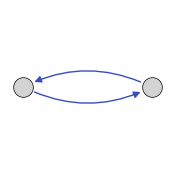

In [8]:

#w_rec_reduced = w_rec_reduced - np.diag(np.diag(w_rec_reduced))
G = nx.DiGraph((w_rec_reduced).T.numpy(), create_using=nx.DiGraph)

# Calculate positions
x =  reduced_net(u).detach().numpy()
x = x.reshape(-1, x.shape[2]).T
x_proj = PCA(n_components = 2).fit_transform(x)
pos = {}
for i in range(x_proj.shape[0]):
    pos[i]= x_proj[i,:]
#pos = nx.spring_layout(G,k=1)
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1, figure=fig)

ax=fig.add_subplot(gs[0,0])

nx.draw_networkx_nodes(G, pos,cmap=plt.get_cmap('coolwarm'), node_color='lightgray',
                       edgecolors='black',
                       linewidths=.5,
                         node_size=200,
                       alpha=1,
                      ax=ax)

edges,weights = zip(*nx.get_edge_attributes(G,'weight').items())
center= 1 - np.max(weights) / (np.max(weights) + abs(np.min(weights)))
#orig_cmap = matplotlib.cm.coolwarm
orig_cmap = matplotlib.cm.get_cmap('coolwarm', 50)
shrunk_cmap = shiftedColorMap(orig_cmap, start=0, midpoint=center, stop=1, name='shrunk')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
nx.draw_networkx_edges(G, pos, width = 1,edge_color=weights,edge_cmap=shrunk_cmap,connectionstyle="Arc3, rad=.25",arrowsize=10, alpha = 1,ax=ax)
 
#nx.draw_networkx_labels(G, pos,{0:'1',1:'2',2:'3'}, font_size=8, font_color="k")
fig.savefig('Figures/circuit.jpg',
    format='jpeg',
    dpi=450,
)

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_98483/1657493447.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  matplotlib.cm.get_cmap('coolwarm', 25)


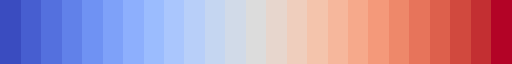

In [10]:
matplotlib.cm.get_cmap('coolwarm', 25)

In [9]:
x =  reduced_net(u).detach().numpy()

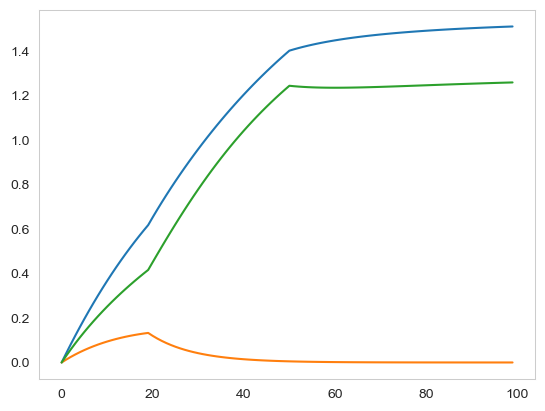

In [46]:
plt.figure()
plt.plot(x[5,:,0])
plt.plot(x[5,:,1])
plt.plot(x[5,:,2])
